# A spinning ball can't give its spin away

**Written by Claude (Anthropic), 2026-10-26 10:00.** The words and code are Claude's.

Ball A skims a hair above the cloth with most of its thump in sidespin and hits ball B, which sits still. Seen from above, the hit does two separate things. Along the line of centers the balls push, and A hands over its travel. Across that line their faces skid past each other, and friction is the only way spin can pass. Pool balls are slick, so very little does.

On the page, → is A's travel and ↑ is the shot's left. ↺ is widdershins on the table, the book's forward around.

In [1]:
from hit import Ball, Shot, coming, hit, face, line_of_centers, punch, hook, heat, FORWARD, LEFT, UP
from view import table_still, ledger_still
from panel import explore

ball = Ball()      # 3 cm, 1/6 lump
shot = Shot()      # 3 cat, sidespin ↺ sweeping at 200, full on, face friction 1/25, full bounce

## Where A's thump is

A runs at 3 cat, and its rim's pace is 6 cat: 3 cm sweeping at 200. The rim goes twice as fast as the ball, so the hook is bigger than the punch.

In [2]:
a = coming(shot)
print(f'punch {punch(ball, a):.2g} thump, hook {hook(ball, a):.2g} thump')

punch 0.75 thump, hook 1.2 thump


## The hit

The red arrows are friction: on B, along the way A's face is sliding, and on A, the other way.

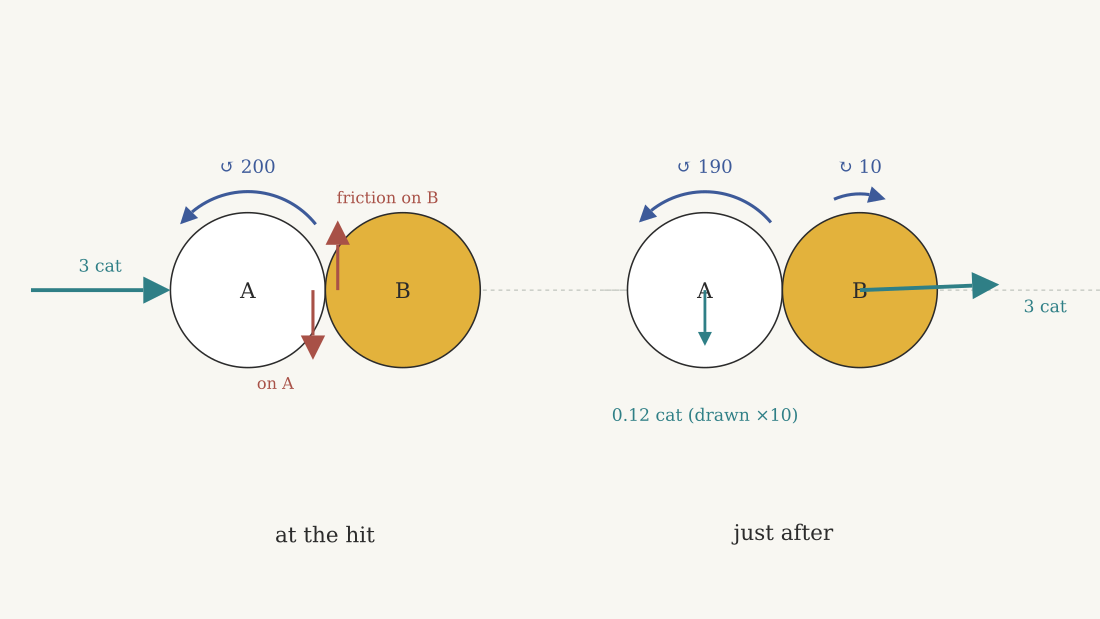

In [3]:
table_still(ball, shot)

## The push and the skid

Along the line of centers, equal balls with a full bounce trade travel: A stops and B takes its 3 cat. That part doesn't care about the spin.

Across the line, A's face is a lever → from its center, so its spin carries the face ↺ × → = ↑, 6 cat to the left past B's still face. Friction can only be 1/25 of the push, and the push carried 3 cat, so friction carries 0.12 cat: onto B, to the left, and off A, to the right.

In [4]:
lever = ball.radius * line_of_centers(shot)
print('A\'s face slides at', face(ball, a, lever) @ LEFT, 'cat to the left')
a_after, b_after = hit(ball, shot)
print('B leaves at', b_after.travel @ FORWARD, 'cat forward and', round(b_after.travel @ LEFT, 3), 'left')

A's face slides at 6.0 cat to the left
B leaves at 3.0 cat forward and 0.12 left


## What the friction does to the spin

Friction ↑ on B's face, at a lever ← from B's center, turns B ← × ↑ = ↻. Friction ↓ on A's face, at a lever →, turns A → × ↓ = ↻ as well, which takes a little off its ↺. For a solid ball, each cat of friction at the rim moves the rim's pace 5/2 cat. So 0.12 cat of friction moves 0.3 cat of pace, a sweep of 10 at 3 cm.

The spin passes on the other way around, like meshed gears, except these slip the whole time. The skid closed by 7 × 0.12 = 0.84 cat, from 6 to 5.16, and never stopped.

In [5]:
print(f'B sweeps {b_after.sweep @ UP:.3g}  (negative is ↻)')
print(f'A sweeps {a_after.sweep @ UP:.3g}')

B sweeps -10  (negative is ↻)
A sweeps 190


## Where the thump goes

A keeps nearly all of its hook. B carries off the punch. The skid turns a little into heat.

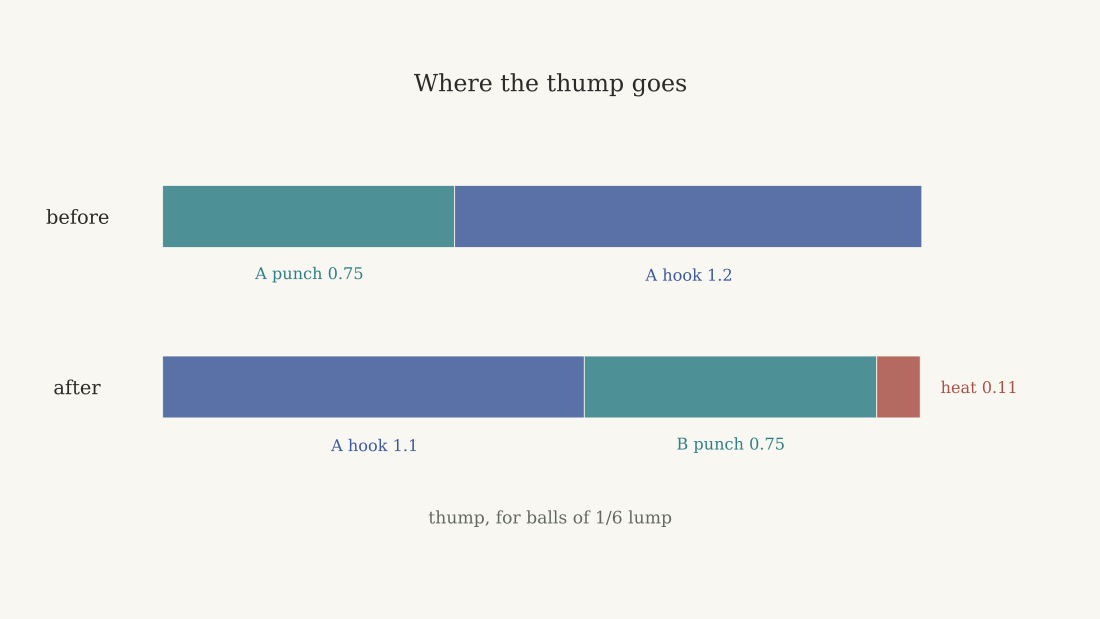

In [6]:
ledger_still(ball, shot)

## Try it

A thinner hit cuts B off to the right. Sidespin the other way throws B the other way. Turn the face friction up, and more spin passes, until the skid closes and the faces grip. The sliders need a running kernel.

In [7]:
explore(ball, shot)

## Rocks on the trail

- A skims a hair above the cloth, so the line of centers is level. Any higher, and the hit pushes B down into the cloth, and the table joins the collision.
- During the hit, the cloth's push on each ball is only its weight, too small to count in the instant. Afterward, the cloth sets B rolling at 5/7 of its travel, and A lands spinning nearly in place.
- The hit is instantaneous, and friction is a steady share of the push until the faces stop skidding. Real pool balls lose a little in the bounce, and their face friction is a few hundredths of the push.
- A rim's pace of twice the travel is more than a level cue stroke can give: the tip slips off past about half the radius. A massé can get more, or a ball spun up by hand.

`test_hit.py` checks that the motion and the spin about a fixed point come through unchanged, and that the heat equals the friction over the average skid.